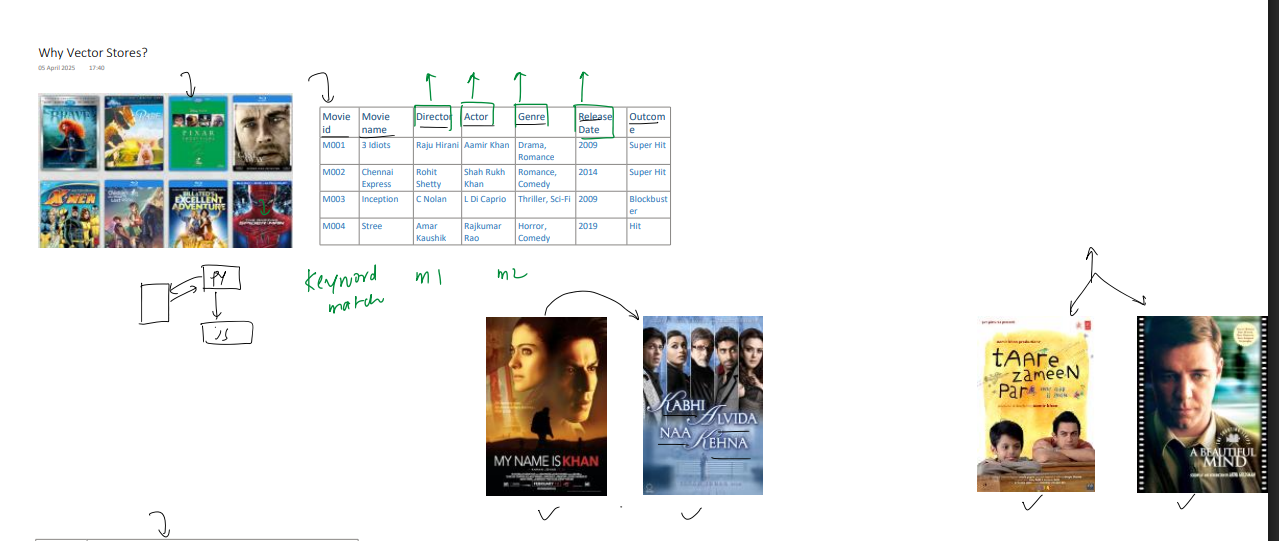

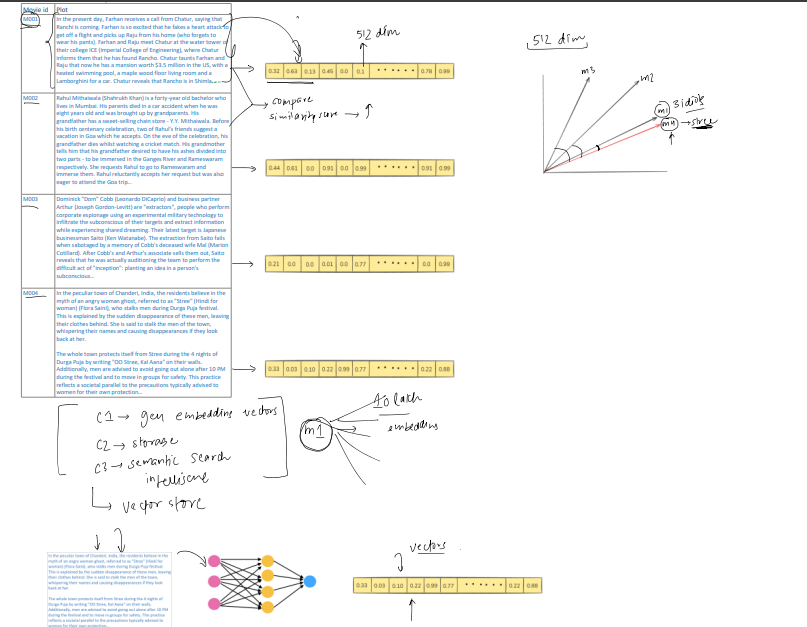

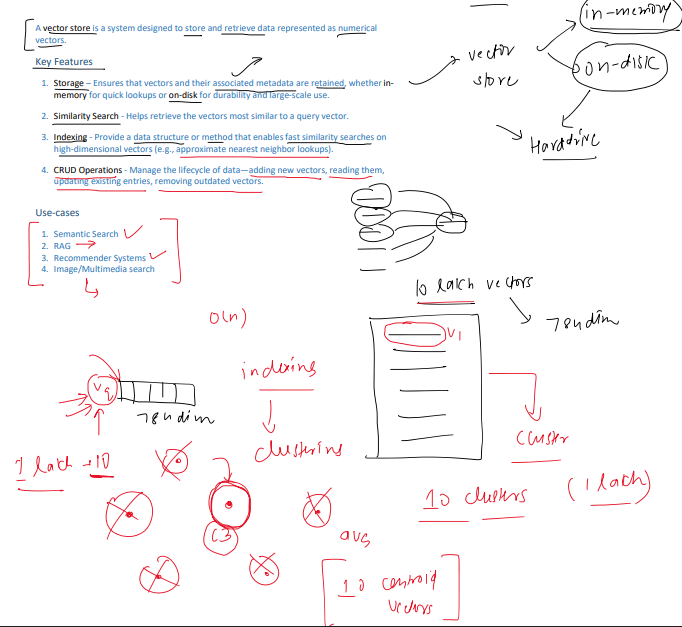

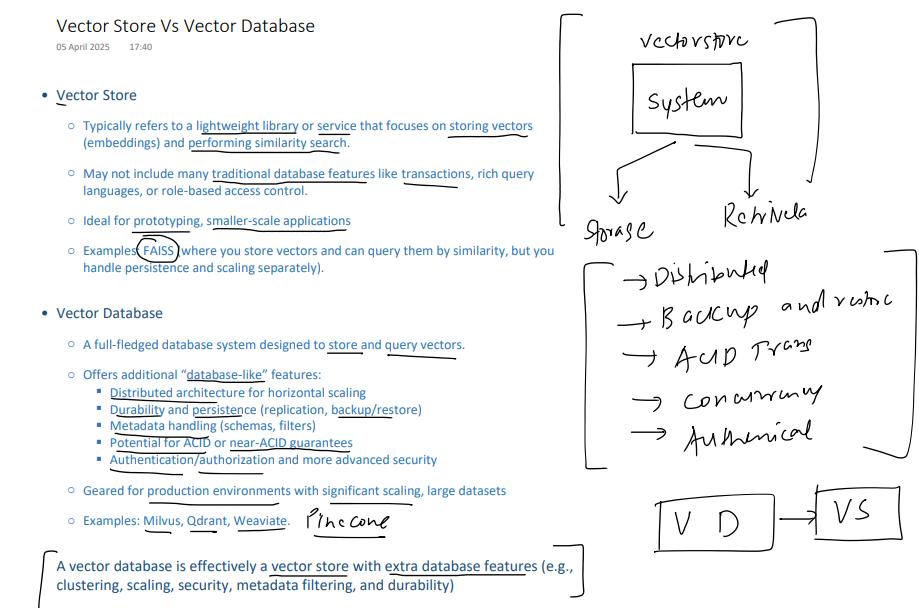

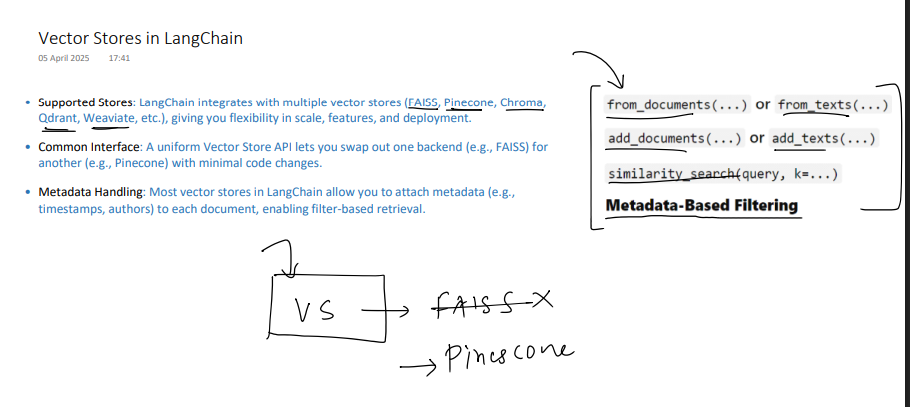

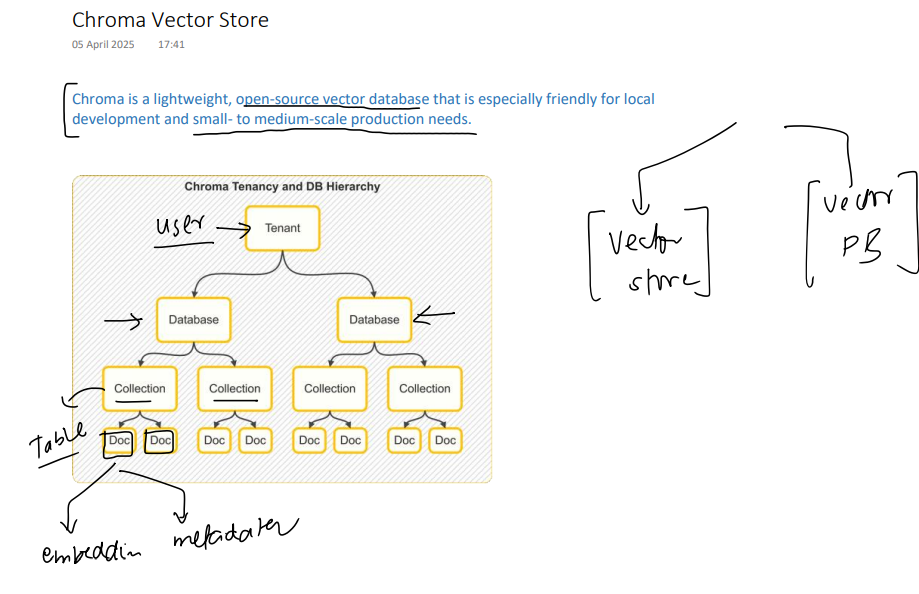

In [3]:
import os
from dotenv import load_dotenv

load_dotenv()

True

In [6]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_chroma import Chroma

from langchain_core.documents import Document

# Create LangChain documents for IPL players

doc1 = Document(
        page_content="Virat Kohli is one of the most successful and consistent batsmen in IPL history. Known for his aggressive batting style and fitness, he has led the Royal Challengers Bangalore in multiple seasons.",
        metadata={"team": "Royal Challengers Bangalore"}
    )
doc2 = Document(
        page_content="Rohit Sharma is the most successful captain in IPL history, leading Mumbai Indians to five titles. He's known for his calm demeanor and ability to play big innings under pressure.",
        metadata={"team": "Mumbai Indians"}
    )
doc3 = Document(
        page_content="MS Dhoni, famously known as Captain Cool, has led Chennai Super Kings to multiple IPL titles. His finishing skills, wicketkeeping, and leadership are legendary.",
        metadata={"team": "Chennai Super Kings"}
    )
doc4 = Document(
        page_content="Jasprit Bumrah is considered one of the best fast bowlers in T20 cricket. Playing for Mumbai Indians, he is known for his yorkers and death-over expertise.",
        metadata={"team": "Mumbai Indians"}
    )
doc5 = Document(
        page_content="Ravindra Jadeja is a dynamic all-rounder who contributes with both bat and ball. Representing Chennai Super Kings, his quick fielding and match-winning performances make him a key player.",
        metadata={"team": "Chennai Super Kings"}
    )

In [8]:
docs = [doc1, doc2, doc3, doc4, doc5]
embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001"
)

vector_store = Chroma(
    persist_directory='my_chroma_db',
    collection_name='sample',
    embedding_function=embeddings
)

In [9]:
# add documents
vector_store.add_documents(docs)

['590e7b0f-e945-40f5-84e9-0c68fa48a066',
 '64ace103-ee76-42c1-b9f6-8ba449b38f32',
 'ba7e3b36-800d-495b-896b-23fdb05c80d3',
 '5b12546e-ca8d-4091-a82c-ba2c9e1d71b2',
 'ae8c6c83-8447-4e4a-b2f5-9e82571f8ea4']

In [10]:
# view documents
vector_store.get(include=['embeddings','documents', 'metadatas'])

{'ids': ['590e7b0f-e945-40f5-84e9-0c68fa48a066',
  '64ace103-ee76-42c1-b9f6-8ba449b38f32',
  'ba7e3b36-800d-495b-896b-23fdb05c80d3',
  '5b12546e-ca8d-4091-a82c-ba2c9e1d71b2',
  'ae8c6c83-8447-4e4a-b2f5-9e82571f8ea4'],
 'embeddings': array([[-0.00982054,  0.02545763,  0.02402782, ...,  0.01414876,
         -0.01560954, -0.00266117],
        [-0.01989721,  0.01092714,  0.01730603, ...,  0.00973945,
         -0.0176257 , -0.00460104],
        [-0.01358705, -0.00359449,  0.01163961, ...,  0.01149882,
         -0.02098301,  0.00373549],
        [-0.01261678, -0.00227585,  0.00470995, ..., -0.00144414,
          0.00646786, -0.00529741],
        [-0.01413488, -0.02750698,  0.01302837, ...,  0.00987475,
         -0.00950909, -0.00272136]], shape=(5, 3072)),
 'documents': ['Virat Kohli is one of the most successful and consistent batsmen in IPL history. Known for his aggressive batting style and fitness, he has led the Royal Challengers Bangalore in multiple seasons.',
  "Rohit Sharma is the m

In [11]:
# search documents
vector_store.similarity_search(
    query='Who among these are a bowler?',
    k=2
)

[Document(id='5b12546e-ca8d-4091-a82c-ba2c9e1d71b2', metadata={'team': 'Mumbai Indians'}, page_content='Jasprit Bumrah is considered one of the best fast bowlers in T20 cricket. Playing for Mumbai Indians, he is known for his yorkers and death-over expertise.'),
 Document(id='ae8c6c83-8447-4e4a-b2f5-9e82571f8ea4', metadata={'team': 'Chennai Super Kings'}, page_content='Ravindra Jadeja is a dynamic all-rounder who contributes with both bat and ball. Representing Chennai Super Kings, his quick fielding and match-winning performances make him a key player.')]

In [12]:
# search with similarity score
vector_store.similarity_search_with_score(
    query='Who among these are a bowler?',
    k=2
)

[(Document(id='5b12546e-ca8d-4091-a82c-ba2c9e1d71b2', metadata={'team': 'Mumbai Indians'}, page_content='Jasprit Bumrah is considered one of the best fast bowlers in T20 cricket. Playing for Mumbai Indians, he is known for his yorkers and death-over expertise.'),
  0.6406819820404053),
 (Document(id='ae8c6c83-8447-4e4a-b2f5-9e82571f8ea4', metadata={'team': 'Chennai Super Kings'}, page_content='Ravindra Jadeja is a dynamic all-rounder who contributes with both bat and ball. Representing Chennai Super Kings, his quick fielding and match-winning performances make him a key player.'),
  0.660536527633667)]

In [19]:
# meta-data filtering
vector_store.similarity_search_with_score(
    query="Who among these are a bowler?",
    filter={"team": "Chennai Super Kings"}
)

[(Document(id='ae8c6c83-8447-4e4a-b2f5-9e82571f8ea4', metadata={'team': 'Chennai Super Kings'}, page_content='Ravindra Jadeja is a dynamic all-rounder who contributes with both bat and ball. Representing Chennai Super Kings, his quick fielding and match-winning performances make him a key player.'),
  0.660536527633667),
 (Document(id='ba7e3b36-800d-495b-896b-23fdb05c80d3', metadata={'team': 'Chennai Super Kings'}, page_content='MS Dhoni, famously known as Captain Cool, has led Chennai Super Kings to multiple IPL titles. His finishing skills, wicketkeeping, and leadership are legendary.'),
  0.7242982387542725)]

In [20]:
# update documents
updated_doc1 = Document(
    page_content="Virat Kohli, the former captain of Royal Challengers Bangalore (RCB), is renowned for his aggressive leadership and consistent batting performances. He holds the record for the most runs in IPL history, including multiple centuries in a single season. Despite RCB not winning an IPL title under his captaincy, Kohli's passion and fitness set a benchmark for the league. His ability to chase targets and anchor innings has made him one of the most dependable players in T20 cricket.",
    metadata={"team": "Royal Challengers Bangalore"}
)

vector_store.update_document(document_id='09a39dc6-3ba6-4ea7-927e-fdda591da5e4', document=updated_doc1)


In [21]:
# view documents
vector_store.get(include=['embeddings','documents', 'metadatas'])

{'ids': ['590e7b0f-e945-40f5-84e9-0c68fa48a066',
  '64ace103-ee76-42c1-b9f6-8ba449b38f32',
  'ba7e3b36-800d-495b-896b-23fdb05c80d3',
  '5b12546e-ca8d-4091-a82c-ba2c9e1d71b2',
  'ae8c6c83-8447-4e4a-b2f5-9e82571f8ea4'],
 'embeddings': array([[-0.00982054,  0.02545763,  0.02402782, ...,  0.01414876,
         -0.01560954, -0.00266117],
        [-0.01989721,  0.01092714,  0.01730603, ...,  0.00973945,
         -0.0176257 , -0.00460104],
        [-0.01358705, -0.00359449,  0.01163961, ...,  0.01149882,
         -0.02098301,  0.00373549],
        [-0.01261678, -0.00227585,  0.00470995, ..., -0.00144414,
          0.00646786, -0.00529741],
        [-0.01413488, -0.02750698,  0.01302837, ...,  0.00987475,
         -0.00950909, -0.00272136]], shape=(5, 3072)),
 'documents': ['Virat Kohli is one of the most successful and consistent batsmen in IPL history. Known for his aggressive batting style and fitness, he has led the Royal Challengers Bangalore in multiple seasons.',
  "Rohit Sharma is the m

In [27]:
# delete document
vector_store.delete(ids=['64ace103-ee76-42c1-b9f6-8ba449b38f32'])

In [28]:
# view documents
vector_store.get(include=['embeddings','documents', 'metadatas'])

{'ids': ['590e7b0f-e945-40f5-84e9-0c68fa48a066',
  'ba7e3b36-800d-495b-896b-23fdb05c80d3',
  '5b12546e-ca8d-4091-a82c-ba2c9e1d71b2',
  'ae8c6c83-8447-4e4a-b2f5-9e82571f8ea4'],
 'embeddings': array([[-0.00982054,  0.02545763,  0.02402782, ...,  0.01414876,
         -0.01560954, -0.00266117],
        [-0.01358705, -0.00359449,  0.01163961, ...,  0.01149882,
         -0.02098301,  0.00373549],
        [-0.01261678, -0.00227585,  0.00470995, ..., -0.00144414,
          0.00646786, -0.00529741],
        [-0.01413488, -0.02750698,  0.01302837, ...,  0.00987475,
         -0.00950909, -0.00272136]], shape=(4, 3072)),
 'documents': ['Virat Kohli is one of the most successful and consistent batsmen in IPL history. Known for his aggressive batting style and fitness, he has led the Royal Challengers Bangalore in multiple seasons.',
  'MS Dhoni, famously known as Captain Cool, has led Chennai Super Kings to multiple IPL titles. His finishing skills, wicketkeeping, and leadership are legendary.',
  